# Week 6 · Tabular data with pandas

**CM3801 · CMT309/509** · Thursday 12 November 2026

Last week a numpy array held one type of value, and you reached it by **position**. Most real data arrives as a **table**: named columns of different types, one row per record. Today you meet **pandas**, Python's library for exactly that.

By the end of today you can create a **DataFrame** and read one from a CSV file; inspect, select, filter and sort it (`loc` / `iloc`); summarise groups with `groupby` (split → apply → combine); clean a text column with `.str`; and judge a table by how its data were collected.

Today has two teaching parts and a two-hour lab: **Hour 1** from arrays to labelled tables · **Hour 2** asking questions of a real table · **Lab** CO₂ emissions and renewable energy projects.

### Setup

Run this cell first. It loads numpy and pandas (both already installed in Colab) and a helper, `get_data()`, that finds the course datasets.

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import numpy as np
import pandas as pd
print("pandas", pd.__version__)

## Hour 1 · From arrays to labelled tables

### Tabular data

A lot of the world's data lives in tables: spreadsheets, relational databases, and now table objects in Python. Tables are easy to understand, you can store and read them directly, and they are an excellent tool for answering questions.

* **Columns** are the variables that were measured (weight, age, population, rainfall…).
* **Rows** are single **records**: an order, a year, a customer, an event.

For example, Cardiff's climate: one column per month, one row per measured quantity.

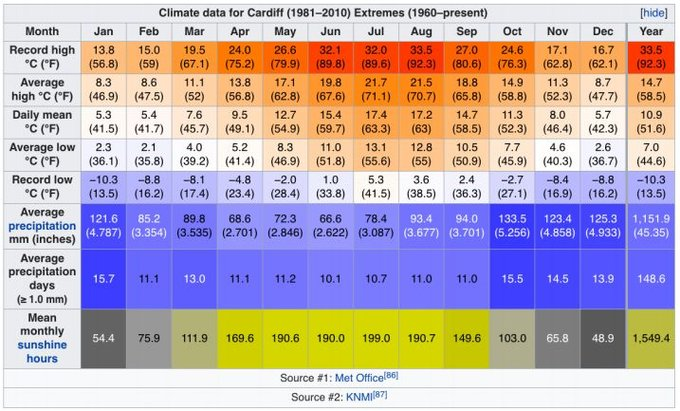

*Table: Wikipedia, "Cardiff" (climate data from the Met Office and KNMI).*

**Discuss:** this table mixes temperatures in °C, rainfall in mm, sunshine in hours and the names of the months. Could you store it as **one** numpy array from Week 5? What would you lose?

<details><summary>Answer</summary>

Only by making everything the same type (all text, or dropping the month names), because a numpy array holds **one** dtype. And you would reach "January's rainfall" by remembering a position such as `a[3, 0]`, instead of asking for it by name.

</details>

### From numpy to pandas

```python
import pandas as pd
```

The most used pandas object is the **DataFrame**. It is similar to a 2-D numpy array, but:
* its columns have **names**;
* its rows have an **index** of labels, which can be anything (like dictionary keys) but keeps its order (like a list);
* each column can have its **own type**.

Here is a small numpy array of the population (millions) and area (km²) of England and Wales:

In [ ]:
a = np.array([[53, 130279], [3, 20735]])
print(a.dtype, a[1, 0])

`a[1, 0]` is Wales's population, but only if you remember that row 1 is Wales and column 0 is population. pandas keeps those labels with the data.

### Anatomy of a DataFrame

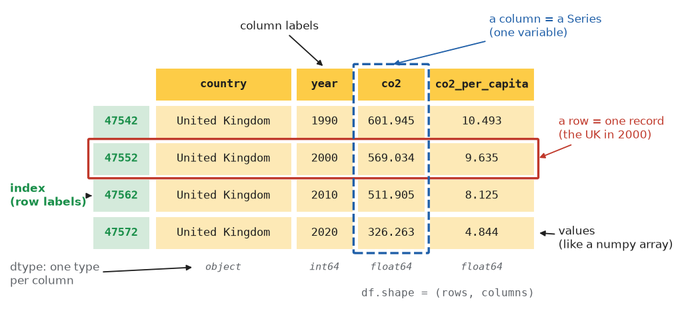

* Each **column** is one variable and has one **dtype** (`object` is pandas' word for text). A single column on its own is a **Series**.
* Each **row** is one record: here, one country in one year (you will use this CO₂ table in the lab).
* The **index** holds the row labels. They are labels, not positions: these four rows keep the numbers they had in the full table.

### Creating a DataFrame

The quickest way is a **dictionary of lists**: each key becomes a column name.

**Predict:** we don't say anything about row labels here. What will the index be?

In [ ]:
df = pd.DataFrame({"population": [1, 2, 3], "area": [100, 200, 300]})
df

Without an explicit index, pandas numbers the rows `0, 1, 2, …`, just like positions.

Now the UK nations, with the nation names as the index. A **Series** is one labelled column; Series that share an index line up by label when they go into a DataFrame. Population is in millions, area in km².

In [ ]:
# ✍️ Type along: three Series that share the nation names as their index, then one DataFrame
countries = ["England", "Wales", "N Ireland", "Scotland"]

<details><summary>Code from class</summary>

```python
countries = ["England", "Wales", "N Ireland", "Scotland"]
pop = pd.Series([53, 3, 1.8, 5.3], index=countries)
area = pd.Series([130279, 20735, 14130, 80077], index=countries)
devolved = pd.Series([False, True, True, True], index=countries)

df = pd.DataFrame({"population": pop, "area": area, "devolved": devolved})
df
```

</details>

Run the next cell whatever you typed above, so that everyone continues with the same `df`.

In [ ]:
countries = ["England", "Wales", "N Ireland", "Scotland"]
df = pd.DataFrame({"population": [53, 3, 1.8, 5.3],
                   "area": [130279, 20735, 14130, 80077],
                   "devolved": [False, True, True, True]}, index=countries)
df

### Inspecting a DataFrame

Several attributes work exactly as in numpy, and two methods summarise the whole table. These are the first things to run on **any** new table:

| | gives |
|---|---|
| `df.shape` | `(rows, columns)` |
| `df.columns`, `df.dtypes` | the column names; one type per column |
| `df.head()`, `df.tail()` | the first / last five rows |
| `df.info()` | columns, non-missing counts and dtypes in one view |
| `df.describe()` | count, mean, min, max, … of every numeric column |

**Before we run this:** `population` holds `53, 3, 1.8, 5.3` and `area` holds whole numbers. Which dtype will each column get?

In [ ]:
print(df.shape)
df.dtypes

`population` is `float64` (one value, 1.8, has a decimal point, so the whole column becomes float), `area` is `int64` and `devolved` is `bool`: **one type per column**, three types in one table.

In [ ]:
df.describe()

`describe()` only summarises the numeric columns. Run `df.info()` in a cell of your own to see the non-missing counts.

### Selecting, adding and dropping columns

Square brackets with a column name give that column as a Series (`df.population` also works, for names without spaces). Assigning to a new name **adds** a column, computed for every row at once, as in numpy:

In [ ]:
df["density"] = df["population"] * 1_000_000 / df["area"]   # people per km²
df

In [ ]:
df = df.drop(columns="density")    # drop() returns a new table; assign it to keep the change
list(df.columns)

### Selecting rows and columns: `loc` and `iloc`

| | selects by | a slice `a:b` |
|---|---|---|
| `df.loc[rows, columns]` | **labels** (index labels, column names) | **includes** `b` |
| `df.iloc[rows, columns]` | **positions** (0, 1, 2, …) | **excludes** `b`, like a list |

**Predict:** does `df.loc["England":"Wales"]` include Wales? Does `df.iloc[0:1]`?

In [ ]:
print(df.loc["England":"Wales"])
print()
print(df.iloc[0:1])

`loc` **includes** the stop label, so Wales is in. `iloc` behaves like list slicing and stops **before** position 1, so you only get England. (With labels there is no "one before the next label", so an inclusive stop is the natural choice.)

Rows and columns can be selected together, and a **list** of labels or positions picks exactly those (*fancy indexing*):

In [ ]:
print(df.loc["England":"Wales", "area"])
print(df.iloc[1, :])                         # the row at position 1, all columns
print(df.loc[["Scotland", "Wales"], ["area"]])

**Your turn:** select the **shaded** block (the `area` and `devolved` values of Wales and N Ireland), once with `loc` and once with `iloc`.

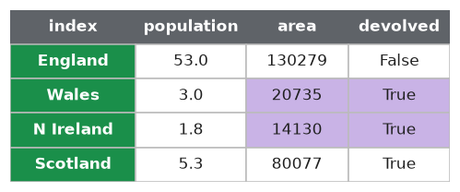

In [ ]:
# with loc:

# with iloc:
# your code here

<details><summary>Answer</summary>

```python
df.loc["Wales":"N Ireland", "area":]   # "area": = from area to the last column
df.iloc[1:3, 1:]
```
`"N Ireland"` is **included** by `loc` (a label stop), while `iloc` stops **before** position 3.

</details>

### Filtering rows with a Boolean mask

In many respects a DataFrame behaves like a numpy array. A comparison on a column gives one `True`/`False` per row (a Boolean Series), and `df[mask]` keeps the `True` rows.

**Before we run this:** which nations have an area above 50,000 km²?

In [ ]:
print(df["area"] > 50000)
df[df["area"] > 50000]

England and Scotland. Combine conditions with `&` (and) and `|` (or), with brackets around each one, as in Week 5. `query()` writes the same question as text:

In [ ]:
print(df[(df["area"] > 50000) & (df["devolved"])])
df.query("area > 50000 and devolved")

### Takeaways: labelled tables

* A **DataFrame** = named columns + an **index** of row labels + one dtype per column. One column is a **Series**.
* Create one from a dictionary (of lists or Series); first look with `shape`, `dtypes`, `head()`, `info()`, `describe()`.
* `df["col"]` selects a column; `df["new"] = …` adds one; `drop(columns=…)` removes one.
* `loc` uses **labels** (stop included); `iloc` uses **positions** (stop excluded).
* A Boolean mask filters rows: `df[df["area"] > 50000]`.

## Hour 2 · Asking questions of a real table

### Reading a CSV file

Real data usually arrives as a file. `pd.read_csv()` turns a CSV file into a DataFrame. Our table has the battle statistics of 800 Pokémon: a small, clean dataset that is good for practising questions.

In [ ]:
pok = pd.read_csv(get_data("pokemon.csv"))
print(pok.shape)
pok.head()

**Quick check:** `pok.dtypes` shows `Name` as `object` and `Legendary` as `bool`. Why these two types?

<details><summary>Answer</summary>

`Name` holds text, and pandas stores text columns with the general `object` dtype. `Legendary` only contains `True`/`False`, so it is a Boolean column. Every numeric statistic (`HP`, `Attack`, …) is `int64`.

</details>

*If `read_csv` ever fails with a `UnicodeDecodeError`, the file is not saved as UTF-8. Government spreadsheets exported from Excel are often in the Windows encoding: `pd.read_csv(path, encoding="cp1252")`. You will meet one in the lab.*

### Missing values are not zeros

pandas marks a missing value as **`NaN`** ("not a number"). `isna()` gives `True` for every missing cell, and `.sum()` counts them per column.

**Predict:** `Type 2` is missing for 386 Pokémon. Does that mean the data is incomplete, or something else?

In [ ]:
pok.isna().sum()

Only `Type 2` has gaps, and here `NaN` means "this Pokémon has **no** second type". `NaN` always means *missing*; what "missing" means depends on the data, so find out before you act:

In [ ]:
print(pok.dropna(subset=["Type 2"]).shape)            # drop: keep only Pokémon with two types
pok["Type 2"].fillna("None").value_counts().head(3)   # fill: name the gap explicitly

* `dropna(subset=[...])` **removes** the rows with a missing value in those columns.
* `fillna(value)` **replaces** the missing values. Filling a missing *number* with 0 would invent data: a missing temperature is not 0 °C.
* `value_counts()` counts how often each value appears in a column.

### Where did this table come from?

Every table was **collected** by someone, for some purpose, before it reached you. How it was collected decides what it can tell you, and what its gaps mean.

| Method | How the values get there | Examples |
|---|---|---|
| **Direct measurement** | instruments or sensors record values | weather stations, smart meters, Week 5's hourly temperatures |
| **Surveys** | people answer questions | a census, a questionnaire |
| **Administrative records** | kept to run a service; analysis is a side use | planning applications, hospital admissions |
| **Curated databases** | a team compiles other people's data into one checked format | Our World in Data, ChEMBL |

**Primary or secondary?**

* **Primary data:** you collect it yourself, for your question. You control the method, but it costs time and money.
* **Secondary data:** someone else collected it, for their purpose. It is cheap and often large, but you inherit their choices and their gaps.

**Six questions to ask of any source**

| Question | Ask |
|---|---|
| **Coverage** | Who or what is included, and who is left out? |
| **Reliability** | How accurate and consistent are the values? |
| **Completeness** | What is missing, and **why**? Gaps often come from the collection method. |
| **Timeliness** | How old is it, and how often is it updated? |
| **Cost / scalability** | What would it cost to collect again, or to collect more? |
| **Documentation / terms of use** | Is the method described? Who may reuse it, and how must it be credited? |

**Discuss (in pairs):** today's lab uses two sources.
* **Our World in Data (OWID) CO₂ data:** a curated compilation of national statistics and research datasets, one row per country and year.
* **The Renewable Energy Planning Database (REPD):** the UK government's register of planning applications for renewable electricity projects.

For each source, name **one strength** and **one limitation**. Then suggest **one other way** someone could collect similar data.

<details><summary>Answer</summary>

| | **OWID CO₂** (curated, secondary) | **REPD** (administrative register) |
|---|---|---|
| Strength | worldwide, many years, documented sources, free to reuse (CC BY 4.0) | official and near-complete for what it covers; updated regularly |
| Limitation | inherits each country's reporting: some columns are missing for most countries in recent years | only projects above a minimum size; it records **applications**, so refused and abandoned projects are in it too; a raw export with messy text |
| Another way | a survey of energy companies; meter readings | operators' own reports; spotting solar and wind farms on satellite images |

Each alternative has its own cost: a survey is slow and depends on who answers; satellite images find farms but not their capacity. In the lab, Task A4 (missing values) and Question B3 (what the REPD's total means) are these limitations in action.

</details>

### Filtering and sorting real data

`sort_values()` orders the rows by a column (`ascending=False` for largest first); `head(n)` keeps the first `n`.

In [ ]:
# ✍️ Type along: the legendary Pokémon that are also very fast (Speed above 100), fastest first

<details><summary>Code from class</summary>

```python
fast_legends = pok[(pok["Legendary"]) & (pok["Speed"] > 100)]
print(fast_legends.shape)                                # (26, 13)
fast_legends.sort_values("Speed", ascending=False)[["Name", "Type 1", "Speed"]].head()
```

</details>

**Your turn:** show the five **fastest** Pokémon of **all** Pokémon whose `Type 1` is `"Water"`, with their `Name` and `Speed`.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
water = pok[pok["Type 1"] == "Water"]
water.sort_values("Speed", ascending=False)[["Name", "Speed"]].head(5)
```
Filter first, then sort, then choose the columns: each step returns a new DataFrame.

</details>

### Group by: split → apply → combine

"The average attack **per type**" is a *group* question. pandas answers it in three steps:
* **split** the rows into groups by a key column;
* **apply** a function (sum, mean, max, …) to every group;
* **combine** the results into one new table.

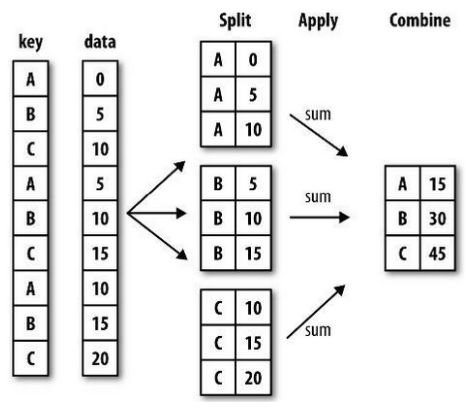

*Figure: W. McKinney, Python for Data Analysis (O'Reilly).*

**Predict:** this is the table in the picture. What will `toy.groupby("key")["data"].sum()` return?

In [ ]:
toy = pd.DataFrame({"key": list("ABCABCABC"),
                    "data": [0, 5, 10, 5, 10, 15, 10, 15, 20]})
toy.groupby("key")["data"].sum()

`A` collects 0 + 5 + 10 = 15, `B` 5 + 10 + 15 = 30 and `C` 10 + 15 + 20 = 45, exactly as in the diagram. The result is a Series whose index is the **group keys**.

Now on the real table:

In [ ]:
# ✍️ Type along: the mean Attack per Type 1, strongest type first; then mean and max together

<details><summary>Code from class</summary>

```python
pok.groupby("Type 1")["Attack"].mean().sort_values(ascending=False).head()
pok.groupby("Type 1")[["HP", "Attack"]].agg(["mean", "max"]).head()
```
`agg()` (short for `aggregate()`) applies several functions at once.

</details>

**Before we run this:** what should `sum()` do with the `Name` column when we group the **whole** table?

In [ ]:
pok.groupby("Type 1").sum().head(2)[["Name", "HP"]]

It glues the names together: in pandas 2, "adding" text means joining it. Older pandas silently dropped text columns, so old code and answers online can mislead you. **Select the numeric columns first** (`groupby("Type 1")["HP"]`), or pass `numeric_only=True`.

**Your turn:** which three `Type 1` values have the highest **average** `Defense`?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
pok.groupby("Type 1")["Defense"].mean().sort_values(ascending=False).head(3)
```
Steel (about 126), Rock (about 101) and Dragon (about 86).

</details>

### Text columns: `.str`

The string methods from Week 1 work on a **whole** text column through `.str`. This dataset stores the Mega forms with odd names such as `VenusaurMega Venusaur`:

In [ ]:
mega = pok["Name"].str.contains("Mega ")      # a Boolean mask, one value per row
print(mega.sum())
pok[mega]["Name"].head(3).tolist()

In [ ]:
print(pok["Name"].str.upper().head(3).tolist())
print(pok["Name"].str.len().max())

**Numbers stored as text.** Data from spreadsheets often contains numbers as text, with stray spaces and blank cells. `.str.strip()` removes the spaces, and `pd.to_numeric(..., errors="coerce")` converts what it can and turns the rest into `NaN`.

**Predict:** what happens to the blank entry?

In [ ]:
capacity = pd.Series(["35.00", "  170.00", "      ", "70.00 "])
clean = pd.to_numeric(capacity.str.strip(), errors="coerce")
print(clean.tolist(), clean.dtype)

The blank becomes `NaN` (missing), and the column is now `float64`, so you can add it up. You'll clean a real government file this way in the lab.

### Takeaways: asking questions of a table

* Ask where a table came from: its collection method, primary or secondary, and the six questions.
* `read_csv` → `shape`, `head()`, `dtypes`, `isna().sum()`: always look before you analyse.
* `NaN` means missing; `dropna` removes, `fillna` replaces. Decide on purpose.
* Filter with masks, order with `sort_values`, pick columns with a list.
* `groupby(key)[column].mean()`: split → apply → combine. Select the columns **before** the function.
* `.str` applies string methods to a whole column; `pd.to_numeric(..., errors="coerce")` turns text into numbers.

## Transition to the lab

**You now know** how to create, inspect, select, filter, sort and group a DataFrame, how to handle missing values, and how to clean a text column.

**The lab** (`W06a_lab_student.ipynb`, two hours) puts all of this to work on two real datasets:
* **Part A:** questions about CO₂ emissions per country (Our World in Data): summary statistics, groups, top-10 tables, and what to do with missing values.
* **Part B:** a raw government file, the UK's Renewable Energy Planning Database. You will find and fix its problems yourself (encoding, stray spaces, numbers stored as text) and then answer questions with `groupby`.

## Week 6 takeaways

* A DataFrame is a labelled table: columns with one dtype each, an index of row labels.
* `loc` = labels (stop included), `iloc` = positions (stop excluded).
* Masks filter, `sort_values` orders, `groupby` splits → applies → combines.
* `NaN` is not zero; `.str` and `pd.to_numeric` clean messy text.
* Every table was collected by someone, for a purpose: judge its coverage, reliability, completeness, timeliness, cost and terms of use before you trust it.

## Where next

**Week 7 · Visualisation.** Tables answer questions; charts make the answers visible. Next week you will choose the right chart for a question and draw it with matplotlib and seaborn, straight from a DataFrame.

Before next week: reopen this notebook, run it top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

**From a numpy array.** Give the column names separately:

In [ ]:
rng = np.random.default_rng(42)
d = pd.DataFrame(rng.random((10, 2)), columns=["rand1", "rand2"])
d.head(3)

**Sorting by the index and ranking.** `sort_index()` orders by the row labels; `rank()` gives each value its rank within its column (ties share the average rank).

In [ ]:
print(df.sort_index())
df.rank()

**Applying a function** to every column (`axis=0`, the default) or every row (`axis=1`):

In [ ]:
print(df.apply(max))
df.drop(columns="devolved").apply(lambda x: x / 10 + 10)

**Combining tables: `merge()`.** Like a database join: rows are matched on a shared column. `how="left"` keeps every row of the left table, and a missing match becomes `NaN`.

In [ ]:
capitals = pd.DataFrame({"country": ["England", "Wales", "Scotland"],
                         "capital": ["London", "Cardiff", "Edinburgh"]})
df.reset_index(names="country").merge(capitals, on="country", how="left")

N Ireland has no match in `capitals`, so its capital is `NaN`.

**One-liners.** A **one-liner** answers a question in **one chained expression**: filter → sort → select. Brackets let it run over several lines; read it from top to bottom. Write it step by step first, and chain only once each step works.

**Your turn:** in one chained expression, show the name and `Attack` of the strongest **Fire**-type Pokémon (`Type 1`).

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
(pok[pok["Type 1"] == "Fire"]
    .sort_values("Attack", ascending=False)
    .head(1)[["Name", "Attack"]])
```
`BlazikenMega Blaziken`, with an attack of 160. Use `.head(3)` for the top three.

</details>

## Credits

The pandas material, its examples and figures follow the *Computational Data Science: Pandas* slides by **Dr Luis Espinosa-Anke**, with thanks. · Split–apply–combine figure: W. McKinney, *Python for Data Analysis* (O'Reilly). · Cardiff climate table: Wikipedia, "Cardiff" (Met Office, KNMI). · Pokémon data: *Pokémon with stats* dataset (Kaggle). · The DataFrame anatomy figure uses the Our World in Data CO₂ dataset (CC BY 4.0).